# Can three EEG channels detect cursor errors across days?

This TKS Iterate tests single-trial EEG classification with fewer electrodes and a later recording. I use participant 1 from BNCI2015-013, who watched a cursor move towards or away from a target. The two recordings were 51 days apart. My Replicate used category averages to describe visual ERPs. Here I train a classifier to distinguish correct and incorrect movements on individual trials.

[Dataset protocol and event codes](https://lampx.tugraz.at/~bci/database/013-2015/description.pdf) · [Chavarriaga and Millán (2010)](https://doi.org/10.1109/TNSRE.2010.2053387)

In Colab, choose **Runtime → Run all**. The two public MATLAB files are downloaded and cached locally. On your own machine, install the dependencies from `requirements.txt` before running.

In [1]:
# Colab's environment may ship different versions. The analysis only needs these libraries.
if "google.colab" in __import__("sys").modules:
    %pip -q install "scikit-learn==1.8.0"

In [2]:
from pathlib import Path
from tempfile import NamedTemporaryFile
from urllib.request import urlopen
import hashlib
import json
import os
import shutil

from IPython.display import SVG, display
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
from scipy.io import loadmat
from scipy.signal import butter, sosfiltfilt
import sklearn
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import balanced_accuracy_score, roc_auc_score, roc_curve

print(f"NumPy {np.__version__} | SciPy {scipy.__version__} | "
      f"scikit-learn {sklearn.__version__} | Matplotlib {matplotlib.__version__}")

NumPy 2.5.5 | SciPy 1.18.1 | scikit-learn 1.8.0 | Matplotlib 3.11.2


## Freeze the design before testing

The three EEG inputs are **Fz, FCz and Cz**, a fixed frontocentral selection motivated by error-related potential research. Both classifiers use the same 0 to 600 ms window after cursor movement and the same shrinkage LDA settings. Each EEG channel contributes its mean voltage in twelve 50 ms bins. Filtering is applied separately to each block and channel. I use the recorded channel signals without recomputing a reference from the 64 channels, so the reduced model's features only use the three selected channels.

The first six blocks of recording 1 are for fitting, the next two are for threshold selection, and the final two are for within-day testing. Recording 2 is held out until both models and thresholds are fixed. The same events are evaluated for both inputs.

[Frontocentral channel selection in published ErrP work](https://pmc.ncbi.nlm.nih.gov/articles/PMC11199896/)

In [3]:
SUBJECT = 1
THREE_CHANNELS = ("Fz", "FCz", "Cz")
BAND_HZ = (1.0, 10.0)
WINDOW_MS = (0, 600)
BIN_WIDTH_MS = 50
FALSE_ALARM_TARGET = 0.10
TRAIN_BLOCKS = range(1, 7)
VALIDATION_BLOCKS = (7, 8)
SAME_DAY_TEST_BLOCKS = (9, 10)
BOOTSTRAP_SEED = 2026
BOOTSTRAP_REPLICATES = 2_000

# The hardware trigger contains the label. Keep it out of the feature matrix.
CORRECT_CODES = (5, 10)
ERROR_CODES = (6, 9)
LEFT_MOVE_CODES = (5, 6)
RECORDING_HASHES = {
    1: "eec75a59a3cb316fad923b7446a1c2fc4dcfc800a1647130063105f9d528594b",
    2: "d0678aa638772753283b174c118b00e8b639b7fef367ccb03bf0ef28c63fe34a",
}
DATA_URL = "https://lampx.tugraz.at/~bci/database/013-2015/"
DATA_DIR = Path(os.environ.get("ITERATE_DATA_DIR", "data"))
OUTPUT_DIR = Path(os.environ.get("ITERATE_OUTPUT_DIR", "."))
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [4]:
def recording_file(session):
    name = f"Subject{SUBJECT:02d}_s{session}.mat"
    destination = DATA_DIR / name
    if not destination.exists():
        with NamedTemporaryFile(dir=DATA_DIR, suffix=".part", delete=False) as download:
            partial = Path(download.name)
        try:
            with urlopen(DATA_URL + name, timeout=90) as response, partial.open("wb") as target:
                shutil.copyfileobj(response, target)
            partial.replace(destination)
        finally:
            partial.unlink(missing_ok=True)
    return destination


def extract_recording(session):
    path = recording_file(session)
    with path.open("rb") as source:
        file_hash = hashlib.file_digest(source, "sha256").hexdigest()
    if file_hash != RECORDING_HASHES[session]:
        raise ValueError(f"Unexpected checksum for {path}. Check the source or replace the cached file.")
    try:
        runs = np.atleast_1d(loadmat(path, squeeze_me=True, struct_as_record=False)["run"])
    except (OSError, ValueError) as exc:
        raise RuntimeError(f"Cannot read {path}. Remove the cached copy and retry.") from exc
    if len(runs) != 10:
        raise ValueError(f"Expected 10 blocks in session {session}, found {len(runs)}.")

    feature_blocks, label_blocks, direction_blocks, block_ids = [], [], [], []
    channels = None
    edge_drops = 0

    for number, run in enumerate(runs, start=1):
        header = run.header
        if (int(header.Subject), int(header.Session)) != (SUBJECT, session):
            raise ValueError(f"Unexpected participant or session in block {number}.")
        names = tuple(str(name).strip() for name in np.ravel(header.Label))
        # The MATLAB header includes a final Status label absent from the 64 EEG columns.
        if len(names) == 65 and names[-1] == "Status":
            names = names[:-1]
        if channels is None:
            channels = names
        if names != channels or len(set(names)) != 64:
            raise ValueError(f"Unexpected EEG channel layout in block {number}.")

        hz = float(header.SampleRate)
        eeg = np.asarray(run.eeg, dtype=np.float64)
        if eeg.ndim != 2 or eeg.shape[1] != len(channels) or not np.isfinite(eeg).all():
            raise ValueError(f"Unexpected EEG data in block {number}.")
        filtered = sosfiltfilt(butter(4, BAND_HZ, btype="bandpass", fs=hz, output="sos"), eeg, axis=0)

        codes = np.asarray(header.EVENT.TYP, dtype=int).ravel()
        starts = np.asarray(header.EVENT.POS, dtype=int).ravel() - 1  # MATLAB positions are 1-based.
        edges_ms = np.arange(WINDOW_MS[0], WINDOW_MS[1] + BIN_WIDTH_MS, BIN_WIDTH_MS)
        edges = np.rint(edges_ms * hz / 1_000).astype(int)
        movements = np.isin(codes, CORRECT_CODES + ERROR_CODES)
        fits = (starts + edges[0] >= 0) & (starts + edges[-1] <= len(filtered))
        keep = movements & fits
        edge_drops += int(np.sum(movements & ~fits))
        labels = np.isin(codes[keep], ERROR_CODES).astype(int)

        # Average voltage within each fixed time bin for each event and channel.
        features = np.stack([
            filtered[starts[keep, None] + np.arange(begin, end)].mean(axis=1)
            for begin, end in zip(edges[:-1], edges[1:])
        ], axis=-1)
        feature_blocks.append(features)
        label_blocks.append(labels)
        direction_blocks.append(np.isin(codes[keep], LEFT_MOVE_CODES))
        block_ids.append(np.full(len(labels), number))

    result = (np.concatenate(feature_blocks), np.concatenate(label_blocks), np.concatenate(block_ids))
    print(f"Recording {session}: {len(runs)} blocks | "
          f"{int((result[1] == 0).sum())} correct | {int(result[1].sum())} errors | "
          f"{edge_drops} incomplete windows excluded")
    print(f"SHA-256: {file_hash}")
    return *result, channels, np.concatenate(direction_blocks)

In [5]:
day1, labels1, blocks1, channels, _ = extract_recording(1)
all_channels = np.arange(len(channels))
reduced_channels = np.array([channels.index(name) for name in THREE_CHANNELS])
channel_sets = {"64 channels": all_channels, "3 channels": reduced_channels}
print("Fixed reduced input:", ", ".join(channels[i] for i in reduced_channels))

Recording 1: 10 blocks | 371 correct | 118 errors | 0 incomplete windows excluded
SHA-256: eec75a59a3cb316fad923b7446a1c2fc4dcfc800a1647130063105f9d528594b
Fixed reduced input: Fz, FCz, Cz


## Fit on recording 1 and select thresholds

For each model, choose the threshold that detects the most validation errors while producing at most ten false alarms per 100 correct moves. When tied, choose the threshold with fewer false alarms, then the higher threshold. This target applies to validation. The held-out false-alarm rates can differ.

In [6]:
def select_features(data, selected):
    return data[:, selected, :].reshape(len(data), -1)


def score_predictions(labels, predicted):
    error = labels == 1
    correct = ~error
    if not np.any(error) or not np.any(correct):
        raise ValueError("A scored split must contain both correct and incorrect moves.")
    caught = int(np.count_nonzero(predicted & error))
    false_alarms = int(np.count_nonzero(predicted & correct))
    return {
        "correct_moves": int(correct.sum()),
        "error_moves": int(error.sum()),
        "errors_caught": caught,
        "false_alarms": false_alarms,
        "error_recall": caught / error.sum(),
        "false_alarm_rate": false_alarms / correct.sum(),
        "balanced_accuracy": float(balanced_accuracy_score(labels, predicted)),
    }


def select_threshold(labels, scores):
    allowed = []
    for threshold in np.r_[np.inf, np.unique(scores)]:
        metrics = score_predictions(labels, scores >= threshold)
        if metrics["false_alarm_rate"] <= FALSE_ALARM_TARGET:
            allowed.append((metrics["error_recall"], -metrics["false_alarm_rate"], float(threshold)))
    return max(allowed)[2]


train = np.isin(blocks1, TRAIN_BLOCKS)
validation = np.isin(blocks1, VALIDATION_BLOCKS)
within_day = np.isin(blocks1, SAME_DAY_TEST_BLOCKS)
for mask in (train, validation, within_day):
    if np.unique(labels1[mask]).size != 2:
        raise ValueError("Each split must contain both movement labels.")

models = {}
for name, selected in channel_sets.items():
    model = LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")
    model.fit(select_features(day1[train], selected), labels1[train])
    validation_scores = model.predict_proba(select_features(day1[validation], selected))[:, 1]
    threshold = select_threshold(labels1[validation], validation_scores)
    models[name] = (model, selected, threshold)
    row = score_predictions(labels1[validation], validation_scores >= threshold)
    print(f"{name}: threshold {threshold:.4g} | validation errors caught "
          f"{row['errors_caught']}/{row['error_moves']} | false alarms "
          f"{row['false_alarms']}/{row['correct_moves']}")

64 channels: threshold 0.1547 | validation errors caught 23/29 | false alarms 6/77
3 channels: threshold 0.5147 | validation errors caught 17/29 | false alarms 6/77


## Evaluate the locked models

The simple baseline predicts that every movement is correct. In a two-class test with both classes represented, it has 50% balanced accuracy, zero errors detected, and zero false alarms.

In [7]:
day2, labels2, blocks2, channels2, leftward2 = extract_recording(2)
if channels2 != channels:
    raise ValueError("The two recordings must use the same channel ordering.")


def evaluate(data, labels, split):
    preds = {}
    scores_by_model = {}
    for name, (model, selected, threshold) in models.items():
        scores = model.predict_proba(select_features(data, selected))[:, 1]
        scores_by_model[name] = scores
        preds[name] = scores >= threshold
    preds["Always correct"] = np.zeros(len(labels), dtype=bool)
    scores_by_model["Always correct"] = np.zeros(len(labels))
    rows = {name: score_predictions(labels, predicted) for name, predicted in preds.items()}
    print(f"\n{split}")
    for name, row in rows.items():
        row["roc_auc"] = float(roc_auc_score(labels, scores_by_model[name]))
        print(f"{name:14} | balanced accuracy {row['balanced_accuracy']:6.1%} | "
              f"ROC AUC {row['roc_auc']:.3f} | "
              f"caught {row['errors_caught']:3}/{row['error_moves']:<3} | "
              f"false alarms {row['false_alarms']:3}/{row['correct_moves']:<3}")
    return rows, preds, scores_by_model


same_results, _, _ = evaluate(day1[within_day], labels1[within_day], "Recording 1, held-out blocks")
later_results, later_predictions, later_scores = evaluate(day2, labels2, "Recording 2, 51 days later")
metrics_by_split = {"Recording 1": same_results, "Recording 2": later_results}

Recording 2: 10 blocks | 438 correct | 117 errors | 0 incomplete windows excluded
SHA-256: d0678aa638772753283b174c118b00e8b639b7fef367ccb03bf0ef28c63fe34a

Recording 1, held-out blocks
64 channels    | balanced accuracy  82.0% | ROC AUC 0.916 | caught  14/18  | false alarms  10/73 
3 channels     | balanced accuracy  75.0% | ROC AUC 0.777 | caught   9/18  | false alarms   0/73 
Always correct | balanced accuracy  50.0% | ROC AUC 0.500 | caught   0/18  | false alarms   0/73 

Recording 2, 51 days later
64 channels    | balanced accuracy  87.6% | ROC AUC 0.940 | caught  97/117 | false alarms  34/438
3 channels     | balanced accuracy  78.9% | ROC AUC 0.892 | caught  69/117 | false alarms   5/438
Always correct | balanced accuracy  50.0% | ROC AUC 0.500 | caught   0/117 | false alarms   0/438


## Audit the held-out scores

ROC AUC measures how often the model ranks an error above a correct move across thresholds. I also calculate it separately for leftward and rightward movements to see whether the separation persists within each direction. These descriptive checks were added after the original run. The channels, features, models and thresholds are the same as in that run.

In [8]:
direction_checks = {}
for direction, mask in (("Leftward", leftward2), ("Rightward", ~leftward2)):
    observed = labels2[mask]
    counts = {"errors": int(observed.sum()), "correct": int((observed == 0).sum())}
    scores = {name: float(roc_auc_score(observed, later_scores[name][mask]))
              for name in channel_sets}
    direction_checks[direction] = {**counts, "roc_auc": scores}
    print(f"{direction}: {counts['errors']} errors and {counts['correct']} correct. "
          + ", ".join(f"{name} AUC {value:.3f}" for name, value in scores.items()))

Leftward: 74 errors and 210 correct. 64 channels AUC 0.952, 3 channels AUC 0.903
Rightward: 43 errors and 228 correct. 64 channels AUC 0.920, 3 channels AUC 0.870


In [9]:
# Resample whole blocks and pair the two models on each resample.
# This describes variability across blocks within recording 2 of this participant.
block_members = [np.flatnonzero(blocks2 == block) for block in np.unique(blocks2)]
generator = np.random.default_rng(BOOTSTRAP_SEED)
bootstrap_scores = []

for _ in range(BOOTSTRAP_REPLICATES):
    indices = np.concatenate([block_members[i] for i in generator.integers(
        0, len(block_members), size=len(block_members)
    )])
    observed = labels2[indices]
    if np.unique(observed).size == 2:
        bootstrap_scores.append([
            balanced_accuracy_score(observed, later_predictions[name][indices])
            for name in channel_sets
        ])

paired = np.asarray(bootstrap_scores)
intervals = {name: np.percentile(paired[:, i], (2.5, 97.5)).tolist()
             for i, name in enumerate(channel_sets)}
gap_interval = np.percentile(paired[:, 1] - paired[:, 0], (2.5, 97.5)).tolist()
for name in channel_sets:
    lo, hi = intervals[name]
    value = later_results[name]["balanced_accuracy"]
    print(f"{name}: recording-2 balanced accuracy "
          f"{value:.1%} (block bootstrap 95% interval {lo:.1%} to {hi:.1%})")
later_gap = {
    metric: later_results["3 channels"][metric] - later_results["64 channels"][metric]
    for metric in ("balanced_accuracy", "error_recall", "false_alarm_rate")
}

print(f"Three minus 64 channels, recording 2: {100 * later_gap['balanced_accuracy']:+.1f} percentage points "
      f"(paired 95% interval {100 * gap_interval[0]:+.1f} to {100 * gap_interval[1]:+.1f})")
summary = {
    "participant": SUBJECT,
    "days_between_recordings": 51,
    "reduced_channels": THREE_CHANNELS,
    "validation_false_alarm_target": FALSE_ALARM_TARGET,
    "metrics": metrics_by_split,
    "later_balanced_accuracy_intervals": intervals,
    "later_three_minus_64": later_gap,
    "later_balanced_accuracy_difference_interval": gap_interval,
    "recording_2_movement_direction_audit": direction_checks,
    "thresholds_fixed_on_recording_1": {
        name: (threshold if np.isfinite(threshold) else None)
        for name, (_, _, threshold) in models.items()
    },
}
(OUTPUT_DIR / "results.json").write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")

64 channels: recording-2 balanced accuracy 87.6% (block bootstrap 95% interval 84.1% to 90.7%)
3 channels: recording-2 balanced accuracy 78.9% (block bootstrap 95% interval 75.4% to 83.2%)
Three minus 64 channels, recording 2: -8.7 percentage points (paired 95% interval -12.6 to -4.6)


3011

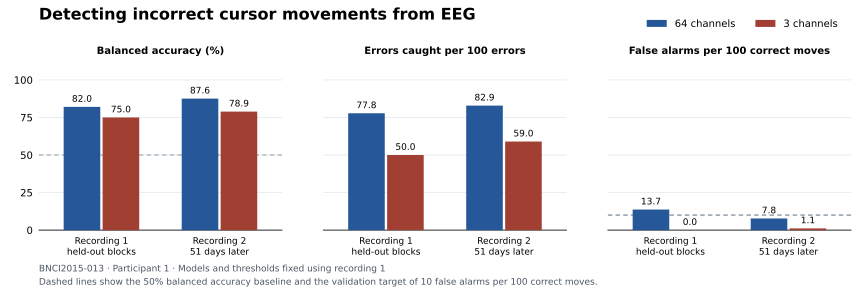

In [10]:
# One figure shows both performance and the cost of asking for feedback.
panels = [
    ("Balanced accuracy (%)", "balanced_accuracy", 50),
    ("Errors caught per 100 errors", "error_recall", None),
    ("False alarms per 100 correct moves", "false_alarm_rate", 10),
]
plt.rcParams.update({"svg.fonttype": "none", "svg.hashsalt": "iterate"})
fig, axes = plt.subplots(1, 3, figsize=(12, 4.1), sharey=True)
splits = list(metrics_by_split)
x = np.arange(len(splits))
colors = ("#265899", "#a03f32")
for ax, (title, metric, reference) in zip(axes, panels):
    if reference is not None:
        ax.axhline(reference, color="#677482", lw=1.1, ls=(0, (4, 3)), zorder=1)
    for i, (name, color) in enumerate(zip(channel_sets, colors)):
        series = [100 * metrics_by_split[split][name][metric] for split in splits]
        bars = ax.bar(x + (i - 0.5) * 0.33, series, 0.31, color=color, label=name, zorder=3)
        ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=9)
    ax.set_title(title, pad=11, fontsize=10, fontweight="bold")
    ax.set_xticks(x, ["Recording 1\nheld-out blocks", "Recording 2\n51 days later"], fontsize=9)
    ax.set_ylim(0, 110)
    ax.set_xlim(-0.53, 1.53)
    ax.set_yticks(np.arange(0, 101, 25))
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="both", length=0, pad=6)
    ax.grid(axis="y", color="#e2e8f0", zorder=0)
fig.suptitle("Detecting incorrect cursor movements from EEG", x=0.045, y=0.975,
             ha="left", fontsize=16, fontweight="bold")
handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, names, loc="upper right", bbox_to_anchor=(0.98, 0.965), ncol=2, frameon=False)
fig.subplots_adjust(left=0.045, right=0.985, bottom=0.22, top=0.78, wspace=0.17)
fig.text(0.045, 0.080, "BNCI2015-013 · Participant 1 · Models and thresholds fixed using recording 1",
         color="#4b5563", fontsize=9)
fig.text(0.045, 0.035, "Dashed lines show the 50% balanced accuracy baseline and the validation target of 10 false alarms per 100 correct moves.",
         color="#4b5563", fontsize=9)
chart = OUTPUT_DIR / "comparison.svg"
fig.savefig(chart, metadata={"Date": None})
fig.savefig(OUTPUT_DIR / "comparison.png", dpi=160)
plt.close(fig)
display(SVG(filename=str(chart)))

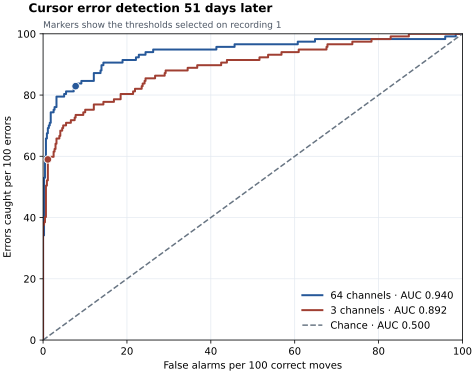

In [11]:
fig, ax = plt.subplots(figsize=(6.6, 5.2), layout="constrained")
for color, name in zip(colors, channel_sets):
    fpr, tpr, _ = roc_curve(labels2, later_scores[name])
    row = later_results[name]
    ax.plot(100 * fpr, 100 * tpr, color=color, linewidth=2,
            label=f"{name} · AUC {row['roc_auc']:.3f}")
    ax.scatter(100 * row["false_alarm_rate"], 100 * row["error_recall"],
               s=58, color=color, edgecolor="white", linewidth=0.9, zorder=3)
ax.plot([0, 100], [0, 100], color="#677482", ls="--", label="Chance · AUC 0.500")
ax.set(xlim=(0, 100), ylim=(0, 100), xlabel="False alarms per 100 correct moves",
       ylabel="Errors caught per 100 errors")
fig.suptitle("Cursor error detection 51 days later", x=0.06, ha="left", fontweight="bold")
ax.set_title("Markers show the thresholds selected on recording 1", loc="left", fontsize=9, color="#4b5563")
ax.grid(color="#e2e8f0", linewidth=0.7)
ax.legend(loc="lower right", frameon=False)
chart = OUTPUT_DIR / "recording-2-roc.svg"
fig.savefig(chart, metadata={"Date": None})
plt.close(fig)
display(SVG(filename=str(chart)))

The classifier is evaluated offline using known movement onset times. The three-channel comparison uses a subset of the laboratory recording. Its results can guide a later experiment on interface edits and independent hardware.